# Phase 05B: Teacher A → S1 Feature-KD GPU Preflight

## Mục tiêu

Notebook này chỉ kiểm tra kỹ thuật cho hai arm Phase 5:

- A2: `CE + normalized feature KD`;
- A3: `CE + logit KD + normalized feature KD`.

Teacher A luôn frozen. Student S1 phải nhận gradient từ feature loss.
Không lưu trọng số overfit, không bắt đầu full training và không mở Test Set.

Feature loss:

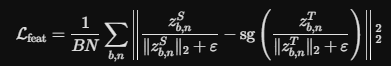

## Kaggle inputs

1. Phase 05A KD improvement entry output.
2. Phase 01 formal output.
3. Phase 02A shared training bundle.
4. Phase 03D Teacher A seed-42 full-run output.
5. Phase 03E Teacher A three-seed aggregate output.
6. MS COCO 2014 images.
7. Offline `openai/clip-vit-base-patch32` model package.

GPU T4 hoặc mạnh hơn. Internet Off. Chạy tuần tự Cell 1 → Cell 9.


## Cell 1 — Environment, authorization và leakage boundary

Xác minh GPU, Phase 05A complete marker, authorization Phase 05B, Teacher A,
Student S1 và Test boundary. Chưa đọc checkpoint payload.


In [1]:
import copy
import csv
import hashlib
import json
import math
import os
import platform
import random
import time
from contextlib import nullcontext
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch


CELL_STARTED_AT = time.perf_counter()
SEED = 42
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path(
    "/kaggle/working//"
    "phase5_teacher_a_s1_feature_kd_gpu_preflight"
)
AUDIT_DIR = OUTPUT_ROOT / "audits"
CONFIG_DIR = OUTPUT_ROOT / "configs"
RESULT_DIR = OUTPUT_ROOT / "results"
CHECKPOINT_DIR = OUTPUT_ROOT / "checkpoints"
MANIFEST_DIR = OUTPUT_ROOT / "manifests"
for directory in [
    OUTPUT_ROOT, AUDIT_DIR, CONFIG_DIR, RESULT_DIR,
    CHECKPOINT_DIR, MANIFEST_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)


def now_utc():
    return datetime.now(timezone.utc).isoformat()


def read_json(path):
    with Path(path).open("r", encoding="utf-8") as handle:
        return json.load(handle)


def write_json(path, payload):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    os.replace(temporary, path)


def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


def exactly_one(name):
    matches = sorted(INPUT_ROOT.rglob(name))
    assert len(matches) == 1, (
        f"Cần đúng một {name}; tìm thấy {len(matches)}: {matches}"
    )
    return matches[0].resolve()


def resolve_inside(root, relative_path):
    root = Path(root).resolve()
    target = (root / relative_path).resolve()
    assert target.is_relative_to(root), (root, target)
    return target


def set_deterministic(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(True, warn_only=False)
    torch.backends.cuda.enable_flash_sdp(False)
    torch.backends.cuda.enable_mem_efficient_sdp(False)
    torch.backends.cuda.enable_math_sdp(True)


assert torch.cuda.is_available(), "Phase 05B yêu cầu GPU."
set_deterministic(SEED)
device = torch.device("cuda")

PHASE1_READY = exactly_one("PHASE1_FORMAL_DELIVERABLES_READY.json")
PHASE2_READY = exactly_one("PHASE2_SHARED_TRAINING_BUNDLE_READY.json")
TEACHER_A_RUN_COMPLETE = exactly_one(
    "TEACHER_A_SEED42_FULL_RUN_COMPLETE.json"
)
TEACHER_A_AGGREGATE_COMPLETE = exactly_one(
    "PHASE3_TEACHER_A_THREE_SEED_COMPLETE.json"
)
PHASE5A_COMPLETE = exactly_one(
    "PHASE5_KD_IMPROVEMENT_ENTRY_COMPLETE.json"
)
PHASE5B_AUTHORIZED = exactly_one(
    "PHASE5_TEACHER_A_S1_FEATURE_KD_PREFLIGHT_AUTHORIZED.json"
)

phase2_ready = read_json(PHASE2_READY)
teacher_run_marker = read_json(TEACHER_A_RUN_COMPLETE)
teacher_aggregate_marker = read_json(TEACHER_A_AGGREGATE_COMPLETE)
phase5a_complete = read_json(PHASE5A_COMPLETE)
phase5b_authorized = read_json(PHASE5B_AUTHORIZED)

assert phase2_ready["status"] == "ready"
assert phase2_ready["full_training_authorized"] is True
assert teacher_run_marker["status"] == "complete"
assert teacher_run_marker["teacher_id"] == "A"
assert int(teacher_run_marker["seed"]) == 42
assert teacher_run_marker["quality_gate_passed"] is True
assert teacher_run_marker["qualified_for_kd"] is True
assert teacher_aggregate_marker["status"] == "complete"
assert teacher_aggregate_marker["qualified_for_kd"] is True
assert phase5a_complete["status"] == "complete"
assert phase5a_complete["anchor_pair"] == "Teacher A -> S1"
assert phase5a_complete["phase05b_preflight_authorized"] is True
assert phase5a_complete["full_training_authorized"] is False
assert phase5b_authorized["status"] == "authorized"
assert phase5b_authorized["teacher_visual_memory"] == "[B,49,256]"
assert phase5b_authorized["student_visual_memory"] == "[B,49,256]"
assert phase5b_authorized["feature_projection"] == "identity"
assert float(phase5b_authorized["lambda_feature"]) == 0.1
assert phase5b_authorized["teacher_frozen"] is True
assert phase5b_authorized["training_authorized"] is False

for marker in [
    teacher_run_marker,
    teacher_aggregate_marker,
    phase5a_complete,
    phase5b_authorized,
]:
    assert marker["test_set_status"] == "sealed"
    assert marker["test_set_used"] is False

write_json(
    AUDIT_DIR / "phase5b_cell01_environment_authorization.json",
    {
        "audit_version": "phase5b_cell01_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "python": platform.python_version(),
        "pytorch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0),
        "seed": SEED,
        "strict_deterministic": True,
        "anchor_pair": "Teacher A -> S1",
        "phase5a_complete": str(PHASE5A_COMPLETE),
        "phase5b_authorized": str(PHASE5B_AUTHORIZED),
        "dataset_read": False,
        "caption_read": False,
        "checkpoint_payload_read": False,
        "optimizer_step_performed": False,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 1 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Anchor                    : Teacher A -> S1")
print("Development seed          : 42")
print("GPU                       :", torch.cuda.get_device_name(0))
print("Strict deterministic      : True")
print("Phase 05A                 : VERIFIED")
print("Phase 05B authorization   : VERIFIED")
print("Full training authorized  : False")
print("Checkpoint payload read   : False")
print("Test Set status           : SEALED")
print("Next                      : verify inputs and checkpoints")


PHASE 05B CELL 1 STATUS
Status                    : PASSED
Anchor                    : Teacher A -> S1
Development seed          : 42
GPU                       : Tesla T4
Strict deterministic      : True
Phase 05A                 : VERIFIED
Phase 05B authorization   : VERIFIED
Full training authorized  : False
Checkpoint payload read   : False
Test Set status           : SEALED
Next                      : verify inputs and checkpoints


## Cell 2 — Manifest, checkpoint và offline CLIP integrity

Xác minh byte-level Phase 05A, Phase 02A, Teacher A registry, Teacher A
seed-42 best checkpoint, Student initialization và offline CLIP source.
Checkpoint chưa được deserialize.


In [2]:
CELL_STARTED_AT = time.perf_counter()


def verify_manifest(root, csv_path, sums_path):
    root = Path(root).resolve()
    with Path(csv_path).open(
        "r", encoding="utf-8", newline=""
    ) as handle:
        rows = list(csv.DictReader(handle))
    expected_lines = []
    for row in rows:
        artifact = resolve_inside(root, row["relative_path"])
        assert artifact.is_file(), artifact
        assert artifact.stat().st_size == int(row["size_bytes"])
        assert sha256_file(artifact) == row["sha256"], artifact
        expected_lines.append(
            f'{row["sha256"]}  {row["relative_path"]}'
        )
    actual_lines = [
        line.strip()
        for line in Path(sums_path).read_text(
            encoding="utf-8"
        ).splitlines()
        if line.strip()
    ]
    assert actual_lines == expected_lines
    return rows


PHASE5A_ROOT = PHASE5A_COMPLETE.parent
phase5a_manifest_csv = resolve_inside(
    PHASE5A_ROOT,
    phase5a_complete["manifest"]["csv"]["relative_path"],
)
phase5a_sums = resolve_inside(
    PHASE5A_ROOT,
    phase5a_complete["manifest"]["sha256sums"]["relative_path"],
)
assert sha256_file(phase5a_manifest_csv) == (
    phase5a_complete["manifest"]["csv"]["sha256"]
)
assert sha256_file(phase5a_sums) == (
    phase5a_complete["manifest"]["sha256sums"]["sha256"]
)
phase5a_rows = verify_manifest(
    PHASE5A_ROOT, phase5a_manifest_csv, phase5a_sums
)
assert len(phase5a_rows) == 12

auth_ref = phase5a_complete["next_authorization"]
assert resolve_inside(
    PHASE5A_ROOT, auth_ref["relative_path"]
) == PHASE5B_AUTHORIZED
assert sha256_file(PHASE5B_AUTHORIZED) == auth_ref["sha256"]

STUDY_CONTRACT_PATH = resolve_inside(
    PHASE5A_ROOT,
    phase5a_complete["study_contract"]["relative_path"],
)
assert sha256_file(STUDY_CONTRACT_PATH) == (
    phase5a_complete["study_contract"]["sha256"]
)
STUDY_CONTRACT = read_json(STUDY_CONTRACT_PATH)
assert STUDY_CONTRACT["status"] == "locked"
assert STUDY_CONTRACT["anchor"]["feature_projection"] == "identity"
assert STUDY_CONTRACT["anchor"]["teacher_frozen"] is True
assert STUDY_CONTRACT["feature_loss"]["lambda_feature"] == 0.1
assert STUDY_CONTRACT["feature_loss"][
    "teacher_stop_gradient"
] is True

PHASE2_ROOT = PHASE2_READY.parent
phase2_manifest_csv = resolve_inside(
    PHASE2_ROOT,
    phase2_ready["manifests"]["csv"]["relative_path"],
)
phase2_sums = resolve_inside(
    PHASE2_ROOT,
    phase2_ready["manifests"]["sha256sums"]["relative_path"],
)
assert sha256_file(phase2_manifest_csv) == (
    phase2_ready["manifests"]["csv"]["sha256"]
)
assert sha256_file(phase2_sums) == (
    phase2_ready["manifests"]["sha256sums"]["sha256"]
)
phase2_rows = verify_manifest(
    PHASE2_ROOT, phase2_manifest_csv, phase2_sums
)
assert len(phase2_rows) == 38

S1_INITIAL_CHECKPOINT = resolve_inside(
    PHASE2_ROOT,
    phase2_ready["required_artifacts"]["s1_encoder_checkpoint"],
)
SHARED_DECODER_INITIAL_CHECKPOINT = resolve_inside(
    PHASE2_ROOT,
    phase2_ready["required_artifacts"]["shared_decoder_checkpoint"],
)
SHARED_DECODER_CONTRACT = exactly_one(
    "shared_transformer_decoder_contract.json"
)
S1_ENCODER_CONTRACT = exactly_one(
    "s1_encoder_adapter_contract.json"
)

teacher_a_registry_path = resolve_inside(
    TEACHER_A_AGGREGATE_COMPLETE.parent,
    teacher_aggregate_marker[
        "checkpoint_registry"
    ]["relative_path"],
)
assert sha256_file(teacher_a_registry_path) == (
    teacher_aggregate_marker["checkpoint_registry"]["sha256"]
)
teacher_a_registry = read_json(teacher_a_registry_path)
seed42_entries = [
    item for item in teacher_a_registry["checkpoints"]
    if int(item["seed"]) == 42
]
assert len(seed42_entries) == 1
teacher_seed42_registry = seed42_entries[0]
TEACHER_A_BEST_CHECKPOINT = exactly_one(
    "teacher_a_seed42_best.pt"
)
assert sha256_file(TEACHER_A_BEST_CHECKPOINT) == (
    teacher_seed42_registry["checkpoint_sha256"]
)
assert TEACHER_A_BEST_CHECKPOINT.stat().st_size == int(
    teacher_seed42_registry["checkpoint_size_bytes"]
)

source_files = teacher_a_registry[
    "pretrained_source_contract"
]["source_files"]
clip_candidates = []
for config_path in INPUT_ROOT.rglob("config.json"):
    candidate = config_path.parent
    if all((candidate / name).is_file() for name in source_files):
        if all(
            sha256_file(candidate / name) == metadata["sha256"]
            and (candidate / name).stat().st_size
            == int(metadata["size_bytes"])
            for name, metadata in source_files.items()
        ):
            clip_candidates.append(candidate.resolve())
clip_candidates = sorted(set(clip_candidates))
assert len(clip_candidates) == 1, clip_candidates
CLIP_SOURCE_DIR = clip_candidates[0]

phase2_by_path = {
    row["relative_path"]: row for row in phase2_rows
}
for checkpoint in [
    S1_INITIAL_CHECKPOINT,
    SHARED_DECODER_INITIAL_CHECKPOINT,
]:
    relative = checkpoint.relative_to(PHASE2_ROOT).as_posix()
    assert relative in phase2_by_path
    assert sha256_file(checkpoint) == (
        phase2_by_path[relative]["sha256"]
    )

write_json(
    AUDIT_DIR / "phase5b_cell02_input_integrity.json",
    {
        "audit_version": "phase5b_cell02_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "phase5a_manifest_rows": len(phase5a_rows),
        "phase2_manifest_rows": len(phase2_rows),
        "study_contract": "verified",
        "teacher_checkpoint_sha256": sha256_file(
            TEACHER_A_BEST_CHECKPOINT
        ),
        "s1_checkpoint_sha256": sha256_file(
            S1_INITIAL_CHECKPOINT
        ),
        "decoder_checkpoint_sha256": sha256_file(
            SHARED_DECODER_INITIAL_CHECKPOINT
        ),
        "clip_source_verified": True,
        "checkpoint_payload_read": False,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 2 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Phase 05A manifest        : 12 / 12 VERIFIED")
print("Phase 02A manifest        : 38 / 38 VERIFIED")
print("Study contract            : VERIFIED")
print("Teacher A registry        : VERIFIED")
print("Teacher A best checkpoint : VERIFIED")
print("S1 initial checkpoint     : VERIFIED")
print("Shared decoder checkpoint : VERIFIED")
print("Offline CLIP source       : VERIFIED")
print("Checkpoint payload read   : False")
print("Test Set status           : SEALED")
print("Next                      : build fixed Train preflight batch")


PHASE 05B CELL 2 STATUS
Status                    : PASSED
Phase 05A manifest        : 12 / 12 VERIFIED
Phase 02A manifest        : 38 / 38 VERIFIED
Study contract            : VERIFIED
Teacher A registry        : VERIFIED
Teacher A best checkpoint : VERIFIED
S1 initial checkpoint     : VERIFIED
Shared decoder checkpoint : VERIFIED
Offline CLIP source       : VERIFIED
Checkpoint payload read   : False
Test Set status           : SEALED
Next                      : build fixed Train preflight batch


## Cell 3 — Fixed Train batch và dual preprocessing

Dùng 8 ảnh Train phân biệt, augmentation tắt, CLIP normalization cho Teacher
và ImageNet normalization cho Student. Không đọc caption text hoặc Test data.


In [3]:
CELL_STARTED_AT = time.perf_counter()
import pyarrow.parquet as pq
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode


PHASE1_ROOT = PHASE1_READY.parent
TRAIN_PARQUET = exactly_one("mscoco_train.parquet")
IMAGE_MANIFEST = exactly_one("mscoco_image_manifest.parquet")


def find_image_leaf(directory_name, prefix):
    candidates = []
    for path in INPUT_ROOT.rglob(directory_name):
        if path.is_dir() and next(path.glob(f"{prefix}*.jpg"), None):
            candidates.append(path.resolve())
    candidates = sorted(set(candidates))
    assert len(candidates) == 1, candidates
    return candidates[0]


TRAIN_LEAF = find_image_leaf("train2014", "COCO_train2014_")
VAL_LEAF = find_image_leaf("val2014", "COCO_val2014_")

manifest_table = pq.read_table(
    IMAGE_MANIFEST,
    columns=[
        "image_id",
        "experiment_split",
        "source_partition",
        "image_path",
    ],
    filters=[("experiment_split", "=", "train")],
)
train_paths = {}
for row in manifest_table.to_pylist():
    image_id = int(row["image_id"])
    leaf = (
        TRAIN_LEAF
        if row["source_partition"] == "train2014"
        else VAL_LEAF
    )
    path = leaf / Path(row["image_path"]).name
    train_paths[image_id] = path
assert len(train_paths) == 113287

fixed_records = []
seen_images = set()
caption_file = pq.ParquetFile(TRAIN_PARQUET)
for record_batch in caption_file.iter_batches(
    batch_size=1024,
    columns=["annotation_id", "image_id", "token_ids"],
):
    for row in record_batch.to_pylist():
        image_id = int(row["image_id"])
        if image_id in seen_images:
            continue
        token_ids = [int(value) for value in row["token_ids"]]
        assert token_ids[0] == 1 and token_ids[-1] == 2
        fixed_records.append(
            {
                "annotation_id": int(row["annotation_id"]),
                "image_id": image_id,
                "image_path": train_paths[image_id],
                "token_ids": token_ids,
            }
        )
        seen_images.add(image_id)
        if len(fixed_records) == 8:
            break
    if len(fixed_records) == 8:
        break
assert len(fixed_records) == 8
assert len({row["image_id"] for row in fixed_records}) == 8
assert all(row["image_path"].is_file() for row in fixed_records)

teacher_transform = transforms.Compose(
    [
        transforms.Resize(
            256, interpolation=InterpolationMode.BICUBIC
        ),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.48145466, 0.4578275, 0.40821073),
            std=(0.26862954, 0.26130258, 0.27577711),
        ),
    ]
)
student_transform = transforms.Compose(
    [
        transforms.Resize(
            256, interpolation=InterpolationMode.BICUBIC
        ),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        ),
    ]
)


class FixedKDPreflightDataset(Dataset):
    def __len__(self):
        return len(fixed_records)

    def __getitem__(self, index):
        record = fixed_records[index]
        with Image.open(record["image_path"]) as image:
            rgb = image.convert("RGB")
            teacher_image = teacher_transform(rgb)
            student_image = student_transform(rgb)
        ids = torch.tensor(record["token_ids"], dtype=torch.long)
        return {
            "image_id": record["image_id"],
            "annotation_id": record["annotation_id"],
            "teacher_image": teacher_image,
            "student_image": student_image,
            "token_ids": ids,
        }


def kd_collate(rows):
    maximum = max(item["token_ids"].numel() for item in rows)
    full = torch.zeros(len(rows), maximum, dtype=torch.long)
    for index, item in enumerate(rows):
        length = item["token_ids"].numel()
        full[index, :length] = item["token_ids"]
    decoder_input_ids = full[:, :-1]
    labels = full[:, 1:]
    return {
        "image_ids": torch.tensor(
            [item["image_id"] for item in rows], dtype=torch.long
        ),
        "annotation_ids": torch.tensor(
            [item["annotation_id"] for item in rows], dtype=torch.long
        ),
        "teacher_images": torch.stack(
            [item["teacher_image"] for item in rows]
        ),
        "student_images": torch.stack(
            [item["student_image"] for item in rows]
        ),
        "decoder_input_ids": decoder_input_ids,
        "decoder_attention_mask": decoder_input_ids.ne(0),
        "labels": labels,
    }


fixed_loader = DataLoader(
    FixedKDPreflightDataset(),
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=kd_collate,
)
FIXED_BATCH = next(iter(fixed_loader))
assert FIXED_BATCH["teacher_images"].shape == (8, 3, 224, 224)
assert FIXED_BATCH["student_images"].shape == (8, 3, 224, 224)
assert FIXED_BATCH["decoder_input_ids"].shape == FIXED_BATCH["labels"].shape
assert int(FIXED_BATCH["labels"].ne(0).sum()) > 0

write_json(
    AUDIT_DIR / "phase5b_cell03_fixed_train_batch.json",
    {
        "audit_version": "phase5b_cell03_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "image_count": 8,
        "unique_images": 8,
        "teacher_tensor_shape": list(
            FIXED_BATCH["teacher_images"].shape
        ),
        "student_tensor_shape": list(
            FIXED_BATCH["student_images"].shape
        ),
        "decoder_shape": list(
            FIXED_BATCH["decoder_input_ids"].shape
        ),
        "augmentation": "disabled",
        "caption_text_read": False,
        "test_parquet_opened": False,
        "test_images_read": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 3 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Fixed Train images        : 8 / 8")
print("Unique images             : 8")
print("Teacher tensor            :", list(FIXED_BATCH["teacher_images"].shape))
print("Student tensor            :", list(FIXED_BATCH["student_images"].shape))
print("Decoder tensor            :", list(FIXED_BATCH["decoder_input_ids"].shape))
print("Augmentation              : DISABLED")
print("Caption text read         : False")
print("Test Parquet opened       : False")
print("Test images read          : False")
print("Test Set status           : SEALED")
print("Next                      : reconstruct and strict-load models")


PHASE 05B CELL 3 STATUS
Status                    : PASSED
Fixed Train images        : 8 / 8
Unique images             : 8
Teacher tensor            : [8, 3, 224, 224]
Student tensor            : [8, 3, 224, 224]
Decoder tensor            : [8, 13]
Augmentation              : DISABLED
Caption text read         : False
Test Parquet opened       : False
Test images read          : False
Test Set status           : SEALED
Next                      : reconstruct and strict-load models


## Cell 4 — Reconstruct Teacher A và Student S1

Strict-load Teacher A best seed 42 cùng Student initialization. Xác minh
Teacher frozen, vocabulary chung và visual memory `[B,49,256]`.


In [4]:
CELL_STARTED_AT = time.perf_counter()
import torch.nn as nn
import torch.nn.functional as F
from torch.torch_version import TorchVersion
from torchvision.models import mobilenet_v3_large
from transformers import CLIPModel


decoder_config = read_json(
    SHARED_DECODER_CONTRACT
)["architecture"]
assert int(decoder_config["vocabulary_size"]) == 10080
assert int(decoder_config["pad_id"]) == 0
assert int(decoder_config["maximum_decoder_steps"]) == 31


class SharedCaptionDecoder(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = dict(config)
        self.vocabulary_size = int(config["vocabulary_size"])
        self.pad_id = int(config["pad_id"])
        self.d_model = int(config["d_model"])
        self.maximum_decoder_steps = int(
            config["maximum_decoder_steps"]
        )
        self.token_embedding = nn.Embedding(
            self.vocabulary_size,
            self.d_model,
            padding_idx=self.pad_id,
        )
        self.position_embedding = nn.Embedding(
            self.maximum_decoder_steps, self.d_model
        )
        self.embedding_dropout = nn.Dropout(
            float(config["dropout"])
        )
        layer = nn.TransformerDecoderLayer(
            d_model=self.d_model,
            nhead=int(config["nhead"]),
            dim_feedforward=int(config["dim_feedforward"]),
            dropout=float(config["dropout"]),
            activation=config["activation"],
            batch_first=True,
            norm_first=True,
            bias=True,
        )
        self.transformer_decoder = nn.TransformerDecoder(
            layer, num_layers=int(config["num_layers"])
        )
        self.final_norm = nn.LayerNorm(self.d_model)
        self.output_bias = nn.Parameter(
            torch.zeros(self.vocabulary_size)
        )

    def forward(
        self,
        decoder_input_ids,
        visual_memory,
        decoder_attention_mask=None,
    ):
        batch, length = decoder_input_ids.shape
        positions = torch.arange(
            length, device=decoder_input_ids.device
        ).unsqueeze(0).expand(batch, -1)
        target = (
            self.token_embedding(decoder_input_ids)
            * math.sqrt(self.d_model)
            + self.position_embedding(positions)
        )
        target = self.embedding_dropout(target)
        causal = torch.triu(
            torch.ones(
                length,
                length,
                dtype=torch.bool,
                device=decoder_input_ids.device,
            ),
            diagonal=1,
        )
        padding = (
            None
            if decoder_attention_mask is None
            else ~decoder_attention_mask.bool()
        )
        hidden = self.transformer_decoder(
            tgt=target,
            memory=visual_memory,
            tgt_mask=causal,
            tgt_key_padding_mask=padding,
        )
        hidden = self.final_norm(hidden)
        return F.linear(
            hidden,
            self.token_embedding.weight,
            self.output_bias,
        )


class TeacherVisualAdapter(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(768, 256)
        self.position_embedding = nn.Parameter(
            torch.zeros(1, 49, 256)
        )
        self.output_norm = nn.LayerNorm(256)

    def forward(self, patches):
        return self.output_norm(
            self.projection(patches) + self.position_embedding
        )


class StudentVisualEncoderAdapter(nn.Module):
    def __init__(self):
        super().__init__()
        model = mobilenet_v3_large(weights=None)
        self.backbone = model.features
        self.projection = nn.Linear(960, 256)
        self.visual_position_embedding = nn.Parameter(
            torch.empty(1, 49, 256)
        )
        self.output_norm = nn.LayerNorm(256)

    def forward(self, images):
        feature = self.backbone(images)
        tokens = feature.flatten(2).transpose(1, 2).contiguous()
        assert tokens.shape[1:] == (49, 960)
        return self.output_norm(
            self.projection(tokens)
            + self.visual_position_embedding
        )


full_clip = CLIPModel.from_pretrained(
    CLIP_SOURCE_DIR, local_files_only=True
)
TEACHER_ENCODER = full_clip.vision_model
del full_clip
TEACHER_ADAPTER = TeacherVisualAdapter()
TEACHER_DECODER = SharedCaptionDecoder(decoder_config)

STUDENT_ENCODER = StudentVisualEncoderAdapter()
STUDENT_DECODER = SharedCaptionDecoder(decoder_config)

with torch.serialization.safe_globals([TorchVersion]):
    teacher_checkpoint = torch.load(
        TEACHER_A_BEST_CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )
    student_encoder_checkpoint = torch.load(
        S1_INITIAL_CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )
    student_decoder_checkpoint = torch.load(
        SHARED_DECODER_INITIAL_CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )

assert teacher_checkpoint["schema_version"] == (
    "phase3_teacher_a_seed42_checkpoint_v1"
)
assert teacher_checkpoint["teacher_id"] == "A"
assert int(teacher_checkpoint["seed"]) == 42
assert teacher_checkpoint["test_set_status"] == "sealed"
assert teacher_checkpoint["test_set_used"] is False

teacher_encoder_state = TEACHER_ENCODER.state_dict()
unknown_teacher_keys = set(
    teacher_checkpoint["encoder_candidate_state"]
) - set(teacher_encoder_state)
assert not unknown_teacher_keys, unknown_teacher_keys
teacher_encoder_state.update(
    teacher_checkpoint["encoder_candidate_state"]
)
TEACHER_ENCODER.load_state_dict(
    teacher_encoder_state, strict=True
)
teacher_adapter_load = TEACHER_ADAPTER.load_state_dict(
    teacher_checkpoint["adapter_state"], strict=True
)
teacher_decoder_load = TEACHER_DECODER.load_state_dict(
    teacher_checkpoint["decoder_state"], strict=True
)
student_encoder_load = STUDENT_ENCODER.load_state_dict(
    student_encoder_checkpoint["state_dict"], strict=True
)
student_decoder_load = STUDENT_DECODER.load_state_dict(
    student_decoder_checkpoint["state_dict"], strict=True
)
for result in [
    teacher_adapter_load,
    teacher_decoder_load,
    student_encoder_load,
    student_decoder_load,
]:
    assert not result.missing_keys
    assert not result.unexpected_keys

STUDENT_ENCODER_INITIAL_STATE = {
    key: value.detach().cpu().clone()
    for key, value in STUDENT_ENCODER.state_dict().items()
}
STUDENT_DECODER_INITIAL_STATE = {
    key: value.detach().cpu().clone()
    for key, value in STUDENT_DECODER.state_dict().items()
}

del teacher_checkpoint
del student_encoder_checkpoint
del student_decoder_checkpoint
del teacher_encoder_state

TEACHER_ENCODER = TEACHER_ENCODER.to(device)
TEACHER_ADAPTER = TEACHER_ADAPTER.to(device)
TEACHER_DECODER = TEACHER_DECODER.to(device)
STUDENT_ENCODER = STUDENT_ENCODER.to(device)
STUDENT_DECODER = STUDENT_DECODER.to(device)

for module in [
    TEACHER_ENCODER,
    TEACHER_ADAPTER,
    TEACHER_DECODER,
]:
    module.eval()
    for parameter in module.parameters():
        parameter.requires_grad_(False)


def teacher_forward(images, decoder_ids, decoder_mask):
    output = TEACHER_ENCODER(pixel_values=images)
    patches = output.last_hidden_state[:, 1:, :]
    assert patches.shape[1:] == (49, 768)
    memory = TEACHER_ADAPTER(patches)
    return TEACHER_DECODER(
        decoder_ids, memory, decoder_mask
    )


def student_forward(images, decoder_ids, decoder_mask):
    memory = STUDENT_ENCODER(images)
    assert memory.shape[1:] == (49, 256)
    return STUDENT_DECODER(
        decoder_ids, memory, decoder_mask
    )


def set_student_train_mode():
    STUDENT_ENCODER.train()
    STUDENT_DECODER.train()
    frozen_batchnorm = 0
    for module in STUDENT_ENCODER.modules():
        if isinstance(
            module, nn.modules.batchnorm._BatchNorm
        ):
            module.eval()
            frozen_batchnorm += 1
    assert frozen_batchnorm == 46
    return frozen_batchnorm


teacher_parameter_count = sum(
    parameter.numel()
    for module in [
        TEACHER_ENCODER,
        TEACHER_ADAPTER,
        TEACHER_DECODER,
    ]
    for parameter in module.parameters()
)
student_parameter_count = sum(
    parameter.numel()
    for module in [STUDENT_ENCODER, STUDENT_DECODER]
    for parameter in module.parameters()
)
assert student_parameter_count == 8_990_352
assert all(
    not parameter.requires_grad
    for module in [
        TEACHER_ENCODER,
        TEACHER_ADAPTER,
        TEACHER_DECODER,
    ]
    for parameter in module.parameters()
)

smoke = {
    key: (
        value[:2].to(device)
        if isinstance(value, torch.Tensor)
        else value
    )
    for key, value in FIXED_BATCH.items()
}
with torch.no_grad():
    teacher_logits = teacher_forward(
        smoke["teacher_images"],
        smoke["decoder_input_ids"],
        smoke["decoder_attention_mask"],
    )
    student_logits = student_forward(
        smoke["student_images"],
        smoke["decoder_input_ids"],
        smoke["decoder_attention_mask"],
    )
assert teacher_logits.shape == student_logits.shape
assert teacher_logits.shape[-1] == 10080
assert torch.isfinite(teacher_logits).all()
assert torch.isfinite(student_logits).all()

write_json(
    AUDIT_DIR / "phase5b_cell04_model_load.json",
    {
        "audit_version": "phase5b_cell04_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "teacher": "CLIP ViT-B/32 + shared decoder",
        "student": "MobileNetV3-Large + shared decoder",
        "teacher_checkpoint_sha256": sha256_file(
            TEACHER_A_BEST_CHECKPOINT
        ),
        "student_encoder_checkpoint_sha256": sha256_file(
            S1_INITIAL_CHECKPOINT
        ),
        "student_decoder_checkpoint_sha256": sha256_file(
            SHARED_DECODER_INITIAL_CHECKPOINT
        ),
        "teacher_parameters": teacher_parameter_count,
        "student_parameters": student_parameter_count,
        "teacher_frozen": True,
        "teacher_logits_shape": list(teacher_logits.shape),
        "student_logits_shape": list(student_logits.shape),
        "strict_loads_passed": 5,
        "network_download": False,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 4 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Teacher strict load       : PASSED")
print("Teacher component loads   : 3 / 3 PASSED")
print("Student component loads   : 2 / 2 PASSED")
print("Teacher frozen            : True")
print("Teacher parameters        :", teacher_parameter_count)
print("Student parameters        :", student_parameter_count)
print("Teacher logits            :", list(teacher_logits.shape))
print("Student logits            :", list(student_logits.shape))
print("Vocabulary logits         : 10080")
print("Network download          : False")
print("Full training started     : False")
print("Test Set status           : SEALED")
print("Next                      : verify feature-KD semantics")


def teacher_memory_forward(images):
    output = TEACHER_ENCODER(pixel_values=images)
    patches = output.last_hidden_state[:, 1:, :]
    assert patches.shape[1:] == (49, 768)
    memory = TEACHER_ADAPTER(patches)
    assert memory.shape[1:] == (49, 256)
    return memory


def student_memory_forward(images):
    memory = STUDENT_ENCODER(images)
    assert memory.shape[1:] == (49, 256)
    return memory


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: /kaggle/input/models/nguynthnhdan/clip-vit-base-patch32-offline/pytorch/transformers-pytorch/1/openai_clip-vit-base-patch32_3d74acf9
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


PHASE 05B CELL 4 STATUS
Status                    : PASSED
Teacher strict load       : PASSED
Teacher component loads   : 3 / 3 PASSED
Student component loads   : 2 / 2 PASSED
Teacher frozen            : True
Teacher parameters        : 93425248
Student parameters        : 8990352
Teacher logits            : [2, 13, 10080]
Student logits            : [2, 13, 10080]
Vocabulary logits         : 10080
Network download          : False
Full training started     : False
Test Set status           : SEALED
Next                      : verify feature-KD semantics


## Cell 5 — Feature/logit loss semantic unit tests

Kiểm tra normalized feature MSE bằng 0 với feature giống nhau, bất biến theo
scale dương, Teacher stop-gradient, PAD masking và `lambda_feature=0` trả về
đúng loss A1.


In [5]:
CELL_STARTED_AT = time.perf_counter()
TEMPERATURE = float(
    STUDY_CONTRACT["logit_loss_when_enabled"]["temperature"]
)
ALPHA = float(
    STUDY_CONTRACT["logit_loss_when_enabled"]["alpha"]
)
LAMBDA_FEATURE = float(
    STUDY_CONTRACT["feature_loss"]["lambda_feature"]
)
FEATURE_EPSILON = float(
    STUDY_CONTRACT["feature_loss"]["epsilon"]
)
PAD_ID = 0
assert TEMPERATURE == 4.0
assert ALPHA == 0.5
assert LAMBDA_FEATURE == 0.1
assert FEATURE_EPSILON == 1e-6


def normalized_feature_loss(
    student_memory, teacher_memory, epsilon=FEATURE_EPSILON
):
    assert student_memory.shape == teacher_memory.shape
    assert student_memory.shape[1:] == (49, 256)
    student_norm = F.normalize(
        student_memory.float(), p=2, dim=-1, eps=epsilon
    )
    teacher_norm = F.normalize(
        teacher_memory.detach().float(),
        p=2,
        dim=-1,
        eps=epsilon,
    )
    return F.mse_loss(
        student_norm, teacher_norm, reduction="mean"
    )


def improved_kd_loss_components(
    student_logits,
    teacher_logits,
    student_memory,
    teacher_memory,
    labels,
    alpha=ALPHA,
    temperature=TEMPERATURE,
    lambda_feature=LAMBDA_FEATURE,
):
    valid = labels.ne(PAD_ID)
    valid_count = valid.sum()
    assert int(valid_count) > 0
    vocabulary_size = student_logits.shape[-1]
    assert vocabulary_size == 10080
    assert teacher_logits.shape == student_logits.shape
    ce_sum = F.cross_entropy(
        student_logits.float().reshape(-1, vocabulary_size),
        labels.reshape(-1),
        ignore_index=PAD_ID,
        reduction="sum",
    )
    ce = ce_sum / valid_count
    student_log_probs = F.log_softmax(
        student_logits.float() / temperature, dim=-1
    )
    teacher_probs = F.softmax(
        teacher_logits.detach().float() / temperature,
        dim=-1,
    )
    kl_per_token = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="none",
    ).sum(dim=-1)
    kd_kl_t2 = (
        (kl_per_token * valid).sum()
        / valid_count
        * (temperature ** 2)
    )
    feature = normalized_feature_loss(
        student_memory, teacher_memory
    )
    a1 = (1.0 - alpha) * ce + alpha * kd_kl_t2
    a2 = ce + lambda_feature * feature
    a3 = a1 + lambda_feature * feature
    return {
        "a1": a1,
        "a2": a2,
        "a3": a3,
        "ce": ce,
        "kd_kl_t2": kd_kl_t2,
        "feature": feature,
        "valid_tokens": int(valid_count),
    }


generator = torch.Generator(device=device).manual_seed(52005)
synthetic_memory = torch.randn(
    2, 49, 256, generator=generator, device=device
)
identical_feature = normalized_feature_loss(
    synthetic_memory, synthetic_memory.clone()
)
scaled_feature = normalized_feature_loss(
    synthetic_memory, synthetic_memory.clone() * 3.0
)
assert abs(float(identical_feature)) < 1e-12
assert abs(float(scaled_feature)) < 1e-12

synthetic_logits = torch.randn(
    2, 5, 10080, generator=generator, device=device
)
synthetic_labels = torch.tensor(
    [[4, 5, 6, 2, 0], [7, 8, 9, 10, 2]],
    device=device,
)
base = improved_kd_loss_components(
    synthetic_logits,
    synthetic_logits * 0.5,
    synthetic_memory,
    synthetic_memory * 0.7,
    synthetic_labels,
)
zero_feature_weight = improved_kd_loss_components(
    synthetic_logits,
    synthetic_logits * 0.5,
    synthetic_memory,
    synthetic_memory * 0.7,
    synthetic_labels,
    lambda_feature=0.0,
)
assert torch.equal(
    zero_feature_weight["a3"], zero_feature_weight["a1"]
)
assert torch.isfinite(base["a2"])
assert torch.isfinite(base["a3"])

FEATURE_LOSS_CONTRACT = CONFIG_DIR / (
    "phase5b_verified_feature_kd_loss.json"
)
write_json(
    FEATURE_LOSS_CONTRACT,
    {
        "contract_version": (
            "phase5b_feature_kd_loss_verified_v1"
        ),
        "created_at_utc": now_utc(),
        "status": "verified",
        "feature_formula": (
            "mean((l2_normalize(student)-"
            "stopgrad(l2_normalize(teacher)))^2)"
        ),
        "temperature": TEMPERATURE,
        "alpha": ALPHA,
        "lambda_feature": LAMBDA_FEATURE,
        "epsilon": FEATURE_EPSILON,
        "feature_projection": "identity",
        "teacher_stop_gradient": True,
        "identical_feature_loss": float(identical_feature),
        "positive_scale_invariance": float(scaled_feature),
        "lambda_zero_exact_a1": True,
        "test_set_status": "sealed",
        "test_set_used": False,
    },
)
write_json(
    AUDIT_DIR / "phase5b_cell05_loss_semantics.json",
    {
        "audit_version": "phase5b_cell05_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "identical_features_zero": True,
        "positive_scale_invariance": True,
        "teacher_feature_detached": True,
        "lambda_zero_exact_a1": True,
        "losses_finite": True,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 5 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Temperature / alpha       :", TEMPERATURE, "/", ALPHA)
print("Lambda feature            :", LAMBDA_FEATURE)
print("Identical feature loss    :", float(identical_feature))
print("Positive scale invariance :", float(scaled_feature))
print("Lambda=0 equals A1        : EXACT")
print("Teacher feature detached  : True")
print("Test Set status           : SEALED")
print("Next                      : real-batch gradient audit")


PHASE 05B CELL 5 STATUS
Status                    : PASSED
Temperature / alpha       : 4.0 / 0.5
Lambda feature            : 0.1
Identical feature loss    : 0.0
Positive scale invariance : 1.7028111788167563e-17
Lambda=0 equals A1        : EXACT
Teacher feature detached  : True
Test Set status           : SEALED
Next                      : real-batch gradient audit


## Cell 6 — Real-batch feature-gradient và repeatability audit

Kiểm tra feature-only gradient đi vào Student encoder nhưng không đi vào
decoder; A3 phải tạo gradient hữu hạn cho toàn bộ Student. Teacher không có
gradient. Eval memory/logits phải lặp lại bitwise.


In [6]:
CELL_STARTED_AT = time.perf_counter()
torch.cuda.reset_peak_memory_stats()
batch = {
    key: (
        value.to(device)
        if isinstance(value, torch.Tensor)
        else value
    )
    for key, value in FIXED_BATCH.items()
}

for module in [
    TEACHER_ENCODER, TEACHER_ADAPTER, TEACHER_DECODER
]:
    module.eval()
set_student_train_mode()
for module in [STUDENT_ENCODER, STUDENT_DECODER]:
    module.zero_grad(set_to_none=True)

with torch.no_grad():
    fixed_teacher_memory = teacher_memory_forward(
        batch["teacher_images"]
    ).detach()
    fixed_teacher_logits = TEACHER_DECODER(
        batch["decoder_input_ids"],
        fixed_teacher_memory,
        batch["decoder_attention_mask"],
    ).detach()

student_memory = student_memory_forward(
    batch["student_images"]
)
student_logits = STUDENT_DECODER(
    batch["decoder_input_ids"],
    student_memory,
    batch["decoder_attention_mask"],
)
components = improved_kd_loss_components(
    student_logits,
    fixed_teacher_logits,
    student_memory,
    fixed_teacher_memory,
    batch["labels"],
)
assert all(
    torch.isfinite(components[name])
    for name in ["a1", "a2", "a3", "ce", "kd_kl_t2", "feature"]
)

components["feature"].backward(retain_graph=True)
feature_encoder_gradients = [
    parameter.grad
    for parameter in STUDENT_ENCODER.parameters()
    if parameter.requires_grad
]
assert feature_encoder_gradients
assert all(
    gradient is not None
    and torch.isfinite(gradient).all()
    for gradient in feature_encoder_gradients
)
feature_gradient_l2 = math.sqrt(sum(
    float(gradient.detach().float().pow(2).sum())
    for gradient in feature_encoder_gradients
))
assert feature_gradient_l2 > 0.0
assert all(
    parameter.grad is None
    for parameter in STUDENT_DECODER.parameters()
)

for module in [STUDENT_ENCODER, STUDENT_DECODER]:
    module.zero_grad(set_to_none=True)
components["a3"].backward()
student_gradients = [
    parameter.grad
    for module in [STUDENT_ENCODER, STUDENT_DECODER]
    for parameter in module.parameters()
    if parameter.requires_grad
]
assert student_gradients
assert all(
    gradient is not None
    and torch.isfinite(gradient).all()
    for gradient in student_gradients
)
student_gradient_l2 = math.sqrt(sum(
    float(gradient.detach().float().pow(2).sum())
    for gradient in student_gradients
))
assert student_gradient_l2 > 0.0
assert all(
    parameter.grad is None
    for module in [
        TEACHER_ENCODER, TEACHER_ADAPTER, TEACHER_DECODER
    ]
    for parameter in module.parameters()
)

STUDENT_ENCODER.eval()
STUDENT_DECODER.eval()
with torch.no_grad():
    memory_a = student_memory_forward(
        batch["student_images"][:2]
    )
    logits_a = STUDENT_DECODER(
        batch["decoder_input_ids"][:2],
        memory_a,
        batch["decoder_attention_mask"][:2],
    )
    memory_b = student_memory_forward(
        batch["student_images"][:2]
    )
    logits_b = STUDENT_DECODER(
        batch["decoder_input_ids"][:2],
        memory_b,
        batch["decoder_attention_mask"][:2],
    )
memory_repeat_error = float((memory_a - memory_b).abs().max())
logits_repeat_error = float((logits_a - logits_b).abs().max())
assert memory_repeat_error == 0.0
assert logits_repeat_error == 0.0
peak_memory_mib = (
    torch.cuda.max_memory_allocated() / (1024 ** 2)
)

for module in [STUDENT_ENCODER, STUDENT_DECODER]:
    module.zero_grad(set_to_none=True)

write_json(
    AUDIT_DIR / "phase5b_cell06_feature_gradient.json",
    {
        "audit_version": "phase5b_cell06_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "batch_images": 8,
        "teacher_memory_shape": list(
            fixed_teacher_memory.shape
        ),
        "student_memory_shape": list(student_memory.shape),
        "valid_tokens": components["valid_tokens"],
        "ce": float(components["ce"]),
        "kd_kl_t2": float(components["kd_kl_t2"]),
        "feature_loss": float(components["feature"]),
        "a2_loss": float(components["a2"]),
        "a3_loss": float(components["a3"]),
        "feature_only_encoder_gradient_l2": feature_gradient_l2,
        "feature_only_decoder_gradients": "none",
        "a3_student_gradient_l2": student_gradient_l2,
        "teacher_gradients": "none",
        "memory_repeat_error": memory_repeat_error,
        "logits_repeat_error": logits_repeat_error,
        "peak_gpu_memory_mib": peak_memory_mib,
        "optimizer_step_performed": False,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 6 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Teacher/Student memory    :", (
    list(fixed_teacher_memory.shape),
    list(student_memory.shape),
))
print("CE / KL / feature         :", (
    float(components["ce"]),
    float(components["kd_kl_t2"]),
    float(components["feature"]),
))
print("A2 / A3 loss              :", (
    float(components["a2"]), float(components["a3"])
))
print("Feature encoder grad L2   :", feature_gradient_l2)
print("Feature decoder gradients : NONE")
print("A3 Student grad L2        :", student_gradient_l2)
print("Teacher gradients         : NONE")
print("Memory/logits repeat error:", (
    memory_repeat_error, logits_repeat_error
))
print("Peak GPU memory           :", round(peak_memory_mib, 2), "MiB")
print("Optimizer step performed  : False")
print("Test Set status           : SEALED")
print("Next                      : discarded one-batch overfit")


PHASE 05B CELL 6 STATUS
Status                    : PASSED
Teacher/Student memory    : ([8, 49, 256], [8, 49, 256])
CE / KL / feature         : (11.11884880065918, 4.488132953643799, 0.007803724613040686)
A2 / A3 loss              : (11.11962890625, 7.804271221160889)
Feature encoder grad L2   : 0.005304339744095581
Feature decoder gradients : NONE
A3 Student grad L2        : 4.79339830248965
Teacher gradients         : NONE
Memory/logits repeat error: (0.0, 0.0)
Peak GPU memory           : 871.95 MiB
Optimizer step performed  : False
Test Set status           : SEALED
Next                      : discarded one-batch overfit


/tmp/ipykernel_23/4137017785.py:142: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  "ce": float(components["ce"]),


## Cell 7 — Discarded one-batch A3 overfit gate

Huấn luyện A3 trên 8 ảnh tối đa 150 bước để chứng minh CE, logit và feature
branches có thể cùng tối ưu. Sau kiểm tra phải phục hồi chính xác Student
initialization; không lưu overfit weights.


In [7]:
CELL_STARTED_AT = time.perf_counter()


def restore_student_initial():
    STUDENT_ENCODER.load_state_dict(
        STUDENT_ENCODER_INITIAL_STATE, strict=True
    )
    STUDENT_DECODER.load_state_dict(
        STUDENT_DECODER_INITIAL_STATE, strict=True
    )
    for module in [STUDENT_ENCODER, STUDENT_DECODER]:
        module.zero_grad(set_to_none=True)


def token_accuracy(logits, labels):
    valid = labels.ne(PAD_ID)
    predicted = logits.argmax(dim=-1)
    return float(
        (predicted.eq(labels) & valid).sum() / valid.sum()
    )


def evaluate_fixed_student():
    STUDENT_ENCODER.eval()
    STUDENT_DECODER.eval()
    with torch.no_grad():
        memory = student_memory_forward(
            batch["student_images"]
        )
        logits = STUDENT_DECODER(
            batch["decoder_input_ids"],
            memory,
            batch["decoder_attention_mask"],
        )
        losses = improved_kd_loss_components(
            logits,
            fixed_teacher_logits,
            memory,
            fixed_teacher_memory,
            batch["labels"],
        )
    return {
        "a3": float(losses["a3"]),
        "ce": float(losses["ce"]),
        "kd": float(losses["kd_kl_t2"]),
        "feature": float(losses["feature"]),
        "accuracy": token_accuracy(logits, batch["labels"]),
    }


restore_student_initial()
initial_eval = evaluate_fixed_student()
backbone_parameters = list(
    STUDENT_ENCODER.backbone.parameters()
)
backbone_ids = {id(parameter) for parameter in backbone_parameters}
adapter_parameters = [
    parameter for parameter in STUDENT_ENCODER.parameters()
    if id(parameter) not in backbone_ids
]
decoder_parameters = list(STUDENT_DECODER.parameters())
optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": 2e-4},
        {"params": adapter_parameters, "lr": 1e-3},
        {"params": decoder_parameters, "lr": 1e-3},
    ],
    weight_decay=0.0,
)

curve = []
maximum_steps = 150
minimum_steps = 50
stopped_early = False
for step in range(1, maximum_steps + 1):
    set_student_train_mode()
    optimizer.zero_grad(set_to_none=True)
    memory = student_memory_forward(batch["student_images"])
    logits = STUDENT_DECODER(
        batch["decoder_input_ids"],
        memory,
        batch["decoder_attention_mask"],
    )
    losses = improved_kd_loss_components(
        logits,
        fixed_teacher_logits,
        memory,
        fixed_teacher_memory,
        batch["labels"],
    )
    assert torch.isfinite(losses["a3"])
    losses["a3"].backward()
    gradients = [
        parameter.grad
        for group in optimizer.param_groups
        for parameter in group["params"]
    ]
    assert all(
        gradient is not None
        and torch.isfinite(gradient).all()
        for gradient in gradients
    )
    gradient_norm = float(
        torch.nn.utils.clip_grad_norm_(
            list(STUDENT_ENCODER.parameters())
            + list(STUDENT_DECODER.parameters()),
            max_norm=1.0,
        )
    )
    optimizer.step()
    row = {
        "step": step,
        "a3_loss": float(losses["a3"]),
        "ce": float(losses["ce"]),
        "kd_kl_t2": float(losses["kd_kl_t2"]),
        "feature_loss": float(losses["feature"]),
        "token_accuracy": token_accuracy(
            logits, batch["labels"]
        ),
        "gradient_norm": gradient_norm,
    }
    curve.append(row)
    if step == 1 or step % 25 == 0:
        print(
            f"step={step:03d} | a3={row['a3_loss']:.6f} | "
            f"ce={row['ce']:.6f} | kd={row['kd_kl_t2']:.6f} | "
            f"feat={row['feature_loss']:.6f} | "
            f"acc={row['token_accuracy']:.4f}"
        )
    if step >= minimum_steps and step % 10 == 0:
        current = evaluate_fixed_student()
        ratio = current["a3"] / initial_eval["a3"]
        if ratio <= 0.35 and current["accuracy"] >= 0.75:
            stopped_early = True
            break

final_eval = evaluate_fixed_student()
final_ratio = final_eval["a3"] / initial_eval["a3"]
assert final_ratio <= 0.35
assert final_eval["accuracy"] >= 0.75
assert final_eval["ce"] < initial_eval["ce"]
assert final_eval["kd"] < initial_eval["kd"]
assert final_eval["feature"] < initial_eval["feature"]

curve_path = RESULT_DIR / (
    "phase5b_one_batch_a3_overfit_curve.csv"
)
with curve_path.open(
    "w", encoding="utf-8", newline=""
) as handle:
    writer = csv.DictWriter(
        handle, fieldnames=list(curve[0])
    )
    writer.writeheader()
    writer.writerows(curve)

del optimizer
restore_student_initial()
restored_eval = evaluate_fixed_student()
for key in ["a3", "ce", "kd", "feature", "accuracy"]:
    assert restored_eval[key] == initial_eval[key], (
        key, restored_eval[key], initial_eval[key]
    )

write_json(
    AUDIT_DIR / "phase5b_cell07_one_batch_overfit.json",
    {
        "audit_version": "phase5b_cell07_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "arm": "A3",
        "images": 8,
        "augmentation": "disabled",
        "completed_steps": len(curve),
        "maximum_steps": maximum_steps,
        "stopped_early": stopped_early,
        "initial": initial_eval,
        "final": final_eval,
        "final_loss_ratio": final_ratio,
        "token_accuracy_gate": 0.75,
        "loss_ratio_gate": 0.35,
        "ce_reduced": True,
        "kd_reduced": True,
        "feature_reduced": True,
        "teacher_frozen": True,
        "student_initial_restore_exact": True,
        "overfit_weights_saved": False,
        "optimizer_steps": "sanity_check_only",
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 7 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Arm                       : A3")
print("Completed steps           :", len(curve))
print("Initial / final A3 loss   :", (
    initial_eval["a3"], final_eval["a3"]
))
print("Final loss ratio          :", final_ratio)
print("Final token accuracy      :", final_eval["accuracy"])
print("CE / KD / feature reduced : True / True / True")
print("Initial restore exact     : True")
print("Overfit weights saved     : False")
print("Full training started     : False")
print("Test Set status           : SEALED")
print("Next                      : FP16 repeatability/resources")


step=001 | a3=7.743422 | ce=10.997203 | kd=4.488080 | feat=0.007804 | acc=0.0000
step=025 | a3=0.825588 | ce=0.074854 | kd=1.574801 | feat=0.007602 | acc=1.0000
step=050 | a3=0.381107 | ce=0.041837 | kd=0.718873 | feat=0.007518 | acc=1.0000
PHASE 05B CELL 7 STATUS
Status                    : PASSED
Arm                       : A3
Completed steps           : 50
Initial / final A3 loss   : (7.912407398223877, 0.34806957840919495)
Final loss ratio          : 0.04399035096288485
Final token accuracy      : 1.0
CE / KD / feature reduced : True / True / True
Initial restore exact     : True
Overfit weights saved     : False
Full training started     : False
Test Set status           : SEALED
Next                      : FP16 repeatability/resources


## Cell 8 — FP16 repeatability và resource audit

Chạy A2/A3 forward trong FP16 autocast hai lần, yêu cầu memory/logits/loss
lặp lại chính xác, hữu hạn và không thực hiện optimizer step.


In [8]:
CELL_STARTED_AT = time.perf_counter()
restore_student_initial()
STUDENT_ENCODER.eval()
STUDENT_DECODER.eval()
for module in [
    TEACHER_ENCODER, TEACHER_ADAPTER, TEACHER_DECODER
]:
    module.eval()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


def fp16_snapshot():
    with torch.no_grad(), torch.amp.autocast(
        device_type="cuda", dtype=torch.float16
    ):
        teacher_memory = teacher_memory_forward(
            batch["teacher_images"][:4]
        )
        teacher_logits = TEACHER_DECODER(
            batch["decoder_input_ids"][:4],
            teacher_memory,
            batch["decoder_attention_mask"][:4],
        )
        student_memory = student_memory_forward(
            batch["student_images"][:4]
        )
        student_logits = STUDENT_DECODER(
            batch["decoder_input_ids"][:4],
            student_memory,
            batch["decoder_attention_mask"][:4],
        )
        losses = improved_kd_loss_components(
            student_logits,
            teacher_logits,
            student_memory,
            teacher_memory,
            batch["labels"][:4],
        )
    return {
        "teacher_memory": teacher_memory.detach().clone(),
        "student_memory": student_memory.detach().clone(),
        "student_logits": student_logits.detach().clone(),
        "a2": losses["a2"].detach().clone(),
        "a3": losses["a3"].detach().clone(),
        "feature": losses["feature"].detach().clone(),
    }


snapshot_a = fp16_snapshot()
snapshot_b = fp16_snapshot()
repeat_errors = {
    key: float((snapshot_a[key] - snapshot_b[key]).abs().max())
    for key in snapshot_a
}
assert all(value == 0.0 for value in repeat_errors.values())
assert all(
    torch.isfinite(value).all()
    for value in snapshot_a.values()
)
peak_memory_mib_fp16 = (
    torch.cuda.max_memory_allocated() / (1024 ** 2)
)
assert peak_memory_mib_fp16 < 14_000

write_json(
    AUDIT_DIR / "phase5b_cell08_fp16_resources.json",
    {
        "audit_version": "phase5b_cell08_v1",
        "created_at_utc": now_utc(),
        "status": "passed",
        "mixed_precision": "FP16 autocast",
        "batch_images": 4,
        "repeat_errors": repeat_errors,
        "all_tensors_finite": True,
        "peak_gpu_memory_mib": peak_memory_mib_fp16,
        "gpu_budget_mib": 14000,
        "optimizer_step_performed": False,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
        "elapsed_seconds": time.perf_counter() - CELL_STARTED_AT,
    },
)

print("=" * 72)
print("PHASE 05B CELL 8 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Mixed precision           : FP16 autocast")
print("Batch images              : 4")
print("Repeat errors             :", repeat_errors)
print("All tensors finite        : True")
print("Peak GPU memory           :", (
    round(peak_memory_mib_fp16, 2), "MiB"
))
print("Optimizer step performed  : False")
print("Full training started     : False")
print("Test Set status           : SEALED")
print("Next                      : formal package")


PHASE 05B CELL 8 STATUS
Status                    : PASSED
Mixed precision           : FP16 autocast
Batch images              : 4
Repeat errors             : {'teacher_memory': 0.0, 'student_memory': 0.0, 'student_logits': 0.0, 'a2': 0.0, 'a3': 0.0, 'feature': 0.0}
All tensors finite        : True
Peak GPU memory           : (549.15, 'MiB')
Optimizer step performed  : False
Full training started     : False
Test Set status           : SEALED
Next                      : formal package


## Cell 9 — Package Phase 05B và authorize Phase 05C

Đóng gói audit/contract/curve. Chỉ authorize production trainer readiness;
full A2/A3 training vẫn chưa được phép.


In [9]:
CELL_STARTED_AT = time.perf_counter()
MANIFEST_CSV = MANIFEST_DIR / "phase5b_manifest.csv"
MANIFEST_JSON = MANIFEST_DIR / "phase5b_manifest.json"
SHA256SUMS = MANIFEST_DIR / "phase5b_SHA256SUMS.txt"
COMPLETE_MARKER = OUTPUT_ROOT / (
    "PHASE5_TEACHER_A_S1_FEATURE_KD_GPU_PREFLIGHT_COMPLETE.json"
)
AUTHORIZED_MARKER = OUTPUT_ROOT / (
    "PHASE5_TEACHER_A_S1_FEATURE_KD_"
    "TRAINING_READINESS_AUTHORIZED.json"
)

write_json(
    AUTHORIZED_MARKER,
    {
        "marker_version": (
            "phase5_teacher_a_s1_feature_kd_"
            "training_readiness_authorized_v1"
        ),
        "created_at_utc": now_utc(),
        "status": "authorized",
        "anchor_pair": "Teacher A -> S1",
        "arms": ["A2", "A3"],
        "feature_loss": "token-wise L2-normalized MSE",
        "feature_projection": "identity",
        "temperature": TEMPERATURE,
        "alpha": ALPHA,
        "lambda_feature": LAMBDA_FEATURE,
        "verified_loss_contract": {
            "relative_path": FEATURE_LOSS_CONTRACT.relative_to(
                OUTPUT_ROOT
            ).as_posix(),
            "sha256": sha256_file(FEATURE_LOSS_CONTRACT),
        },
        "required_next_gates": [
            "production image-balanced dataloader",
            "A2/A3 optimizer parameter coverage",
            "AdamW warmup-cosine and FP16 GradScaler",
            "atomic last/best checkpoint",
            "mid-epoch exact resume",
            "teacher-forced Validation",
            "Beam-3 Validation generation",
            "discarded production pilot",
        ],
        "next_phase": (
            "Phase 05C A2/A3 production training readiness"
        ),
        "full_training_authorized": False,
        "test_set_status": "sealed",
        "test_set_used": False,
    },
)

artifact_paths = sorted(
    [
        path for path in OUTPUT_ROOT.rglob("*")
        if path.is_file()
        and path not in {
            MANIFEST_CSV, MANIFEST_JSON, SHA256SUMS,
            COMPLETE_MARKER,
        }
        and not path.name.endswith(".tmp")
    ],
    key=lambda path: path.relative_to(OUTPUT_ROOT).as_posix(),
)
manifest_rows = [
    {
        "relative_path": path.relative_to(
            OUTPUT_ROOT
        ).as_posix(),
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path),
    }
    for path in artifact_paths
]
with MANIFEST_CSV.open(
    "w", encoding="utf-8", newline=""
) as handle:
    writer = csv.DictWriter(
        handle,
        fieldnames=["relative_path", "size_bytes", "sha256"],
    )
    writer.writeheader()
    writer.writerows(manifest_rows)
write_json(
    MANIFEST_JSON,
    {
        "schema_version": "phase5b_manifest_v1",
        "created_at_utc": now_utc(),
        "artifact_count": len(manifest_rows),
        "artifacts": manifest_rows,
    },
)
SHA256SUMS.write_text(
    "".join(
        f'{row["sha256"]}  {row["relative_path"]}\n'
        for row in manifest_rows
    ),
    encoding="utf-8",
)
for row in manifest_rows:
    artifact = resolve_inside(OUTPUT_ROOT, row["relative_path"])
    assert artifact.stat().st_size == int(row["size_bytes"])
    assert sha256_file(artifact) == row["sha256"]

write_json(
    COMPLETE_MARKER,
    {
        "marker_version": (
            "phase5_teacher_a_s1_feature_kd_"
            "gpu_preflight_complete_v1"
        ),
        "created_at_utc": now_utc(),
        "status": "complete",
        "anchor_pair": "Teacher A -> S1",
        "arms_verified": ["A2", "A3"],
        "feature_loss": "token-wise L2-normalized MSE",
        "feature_projection": "identity",
        "temperature": TEMPERATURE,
        "alpha": ALPHA,
        "lambda_feature": LAMBDA_FEATURE,
        "checkpoint_strict_loads_passed": 5,
        "loss_semantics_passed": True,
        "feature_gradient_passed": True,
        "one_batch_overfit_passed": True,
        "fp16_repeatability_passed": True,
        "phase05c_training_readiness_authorized": True,
        "full_training_authorized": False,
        "authorization_marker": {
            "relative_path": AUTHORIZED_MARKER.relative_to(
                OUTPUT_ROOT
            ).as_posix(),
            "sha256": sha256_file(AUTHORIZED_MARKER),
        },
        "manifest": {
            "csv": {
                "relative_path": MANIFEST_CSV.relative_to(
                    OUTPUT_ROOT
                ).as_posix(),
                "sha256": sha256_file(MANIFEST_CSV),
            },
            "json": {
                "relative_path": MANIFEST_JSON.relative_to(
                    OUTPUT_ROOT
                ).as_posix(),
                "sha256": sha256_file(MANIFEST_JSON),
            },
            "sha256sums": {
                "relative_path": SHA256SUMS.relative_to(
                    OUTPUT_ROOT
                ).as_posix(),
                "sha256": sha256_file(SHA256SUMS),
            },
        },
        "manifest_rows": len(manifest_rows),
        "manifest_verification": "all_passed",
        "sanity_optimizer_steps_only": True,
        "full_training_started": False,
        "test_set_status": "sealed",
        "test_set_used": False,
    },
)

print("=" * 72)
print("PHASE 05B CELL 9 STATUS")
print("=" * 72)
print("Status                    : COMPLETE")
print("Teacher / Student         : A / S1")
print("Arms verified             : A2 / A3")
print("Feature loss              : normalized MSE")
print("Strict checkpoint loads   : 5 / 5 PASSED")
print("Loss semantics            : PASSED")
print("Feature gradient          : PASSED")
print("One-batch A3 overfit      : PASSED")
print("FP16 repeatability        : PASSED")
print("Manifest rows             :", len(manifest_rows))
print("Manifest verification     : ALL PASSED")
print("Phase 05C readiness       : AUTHORIZED")
print("Full training authorized  : False")
print("Test Set status           : SEALED")
print("Next                      : Save Version, then Phase 05C")


PHASE 05B CELL 9 STATUS
Status                    : COMPLETE
Teacher / Student         : A / S1
Arms verified             : A2 / A3
Feature loss              : normalized MSE
Strict checkpoint loads   : 5 / 5 PASSED
Loss semantics            : PASSED
Feature gradient          : PASSED
One-batch A3 overfit      : PASSED
FP16 repeatability        : PASSED
Manifest rows             : 11
Manifest verification     : ALL PASSED
Phase 05C readiness       : AUTHORIZED
Full training authorized  : False
Test Set status           : SEALED
Next                      : Save Version, then Phase 05C
